### Capacitação em Processamento Digital de Sinais - VIRTUS CC
Orientador: Edson Porto

Aluno: Lucas de Souza Salvino



### Configurações de ambiente

Inicialmente, preparamos nosso espaço de estudos com as seguintes configurações:

* **numpy:** que serve para realizar operações matriciais e cálculos numéricos pesados com vetores.
* **scipy:** que fornece os algoritmos específicos para o processamento de sinais (como filtros e transformadas).
* **matplotlib:** que serve para plotarmos os gráficos e visualizarmos o comportamento dos sinais.


* **Livro Texto: Processamento Digital de Sinais - Projeto e Análise de Sistemas Paulo S. R. Diniz, Eduardo A. B. da Silva, Sergio L. Netto - 2ª Edição**

**TESTE DE AMBIENTE COM SINAL AMOSTRADO**

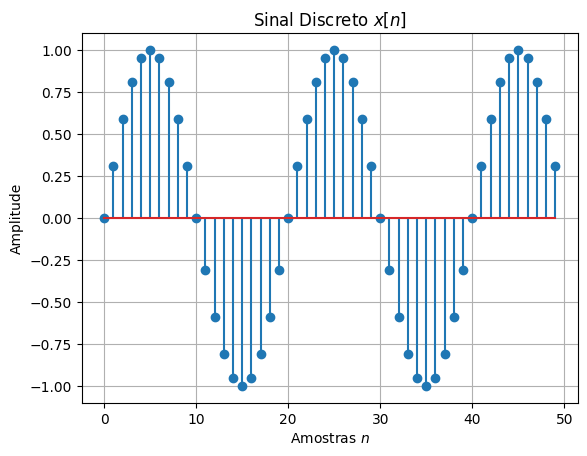

In [6]:
import numpy as np
import matplotlib.pyplot as plt

#Parâmetros do sinal discreto
A = 1.0
f0 = 0.05
phi = 0
n = np.arange(0, 50)

#Equação
x = A * np.sin(2 * np.pi * f0 * n + phi)

#Plotando
plt.stem(n, x)
plt.title('Sinal Discreto $x[n]$')
plt.xlabel('Amostras $n$')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

**Convolução Discreta**

No estudo de Processamento Digital de Sinais, a convolução é a operação fundamental para a análise de Sistemas Lineares e Invariantes no Deslocamento (SLID) (também conhecidos como SLIT - Invariantes no Tempo). A construção desse conceito parte de uma premissa básica: todo e qualquer sinal discreto $x[n]$ pode ser decomposto em uma soma de impulsos unitários ($\delta[n]$) escalonados e deslocados. Devido às propriedades da linearidade e da invariância, se conhecermos a saída de um sistema quando a entrada é um simples impulso unitário — o que chamamos de resposta ao impulso, denotada por $h[n]$ —, podemos descobrir a saída $y[n]$ para absolutamente qualquer sinal de entrada. A relação matemática que define essa saída é a soma de convolução:$$y[n] = x[n] * h[n] = \sum_{k=-\infty}^{\infty} x[k] h[n-k]$$O Mecanismo Físico para calcular o valor da saída $y$ em um instante específico $n$, a equação acima descreve quatro operações sequenciais: Rebatimento: A resposta ao impulso $h[k]$ é invertida (espelhada) no tempo, tornando-se $h[-k]$.Deslocamento: O sinal invertido é deslocado de $n$ posições no tempo, gerando $h[n-k]$. Multiplicação: Os valores do sinal de entrada $x[k]$ e do sinal deslocado $h[n-k]$ são multiplicados ponto a ponto.Soma: Somam-se todos os produtos obtidos. O resultado único dessa soma é o valor do sinal de saída $y[n]$ no instante $n$.

### Relatório 1: Introdução ao Processamento Digital de Sinais

Objetivos:

1. Utilizar pacotes do Python para representar e manipular sinais discretos.

2. Implementação de uma função que receba dois sinais discretos retorne o resultado da convolução discreta entre eles.

3. Análise da complexidade computacional da implementação da convolução. Testar ferramentas de aceleração de código, tais como Numba e CuPy.

## #1
* Implementação de uma função que gera uma porta discreta


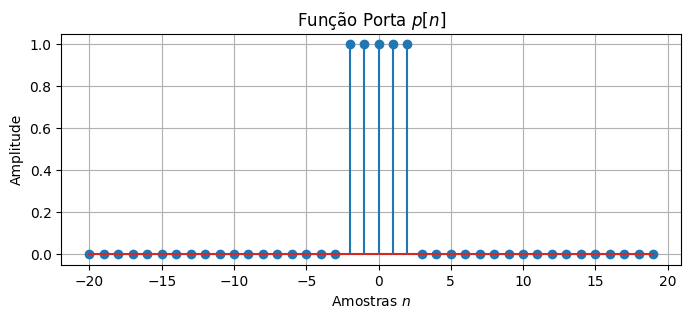

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def porta_discreta(n, tamanho, deslocamento=0):
    """
    n = eixo temporal discreto(array)
    tamanho = número de amostras da porta
    deslocamento = deslocamento em relação ao 0
    """
    #Lógica dos limites da porta
    N_metade = tamanho // 2
    N1 = -N_metade
    N2 = tamanho - N_metade - 1

    porta = np.where(((n - deslocamento) >= N1) & ((n - deslocamento) <= N2), 1, 0)

    return porta

#Definindo o eixo temporal discreto
n = np.arange(-20, 20)

sinal_porta = porta_discreta(n, tamanho=5, deslocamento=0)

#Plotando
plt.figure(figsize=(8, 3))
plt.stem(n, sinal_porta)
plt.title('Função Porta $p[n]$')
plt.xlabel('Amostras $n$')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

* Porta deslocada em 5 unidades para a esquerda:

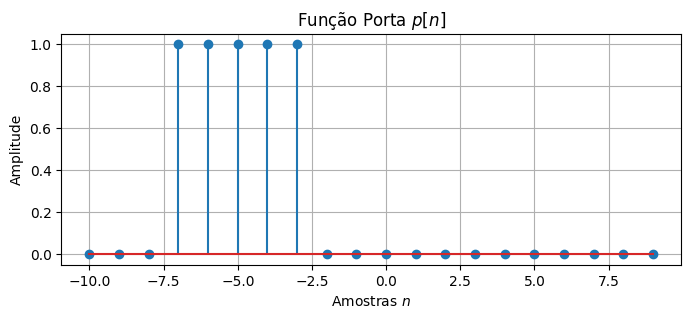

In [8]:

#Definindo o eixo temporal discreto
n = np.arange(-10, 10)

sinal_porta = porta_discreta(n, tamanho=5, deslocamento=-5)

#Plotando
plt.figure(figsize=(8, 3))
plt.stem(n, sinal_porta)
plt.title('Função Porta $p[n]$')
plt.xlabel('Amostras $n$')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

* Implementação de uma função exponencial

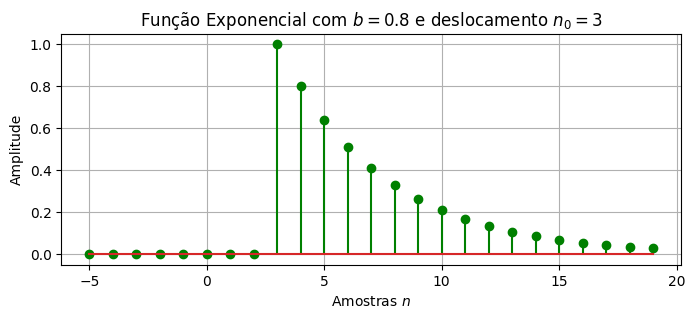

In [12]:
import numpy as np
import matplotlib.pyplot as plt

def exponencial_discreta(n, b, deslocamento=0):
    """
    n = eixo temporal discreto(array)
    b = base da exponencial (float)
    deslocamento =local onde a exponencial começa (int)
    """
    #Lógica do degrau unitário deslocado
    degrau = np.where(n >= deslocamento, 1, 0)

    exponencial = (float(base) ** (n - deslocamento)) * degrau

    return exponencial

#Criando o eixo temporal
n = np.arange(-5, 20)

base = 0.8
sinal_exp = exponencial_discreta(n, base, deslocamento=3)

# Plotando
plt.figure(figsize=(8, 3))
plt.stem(n, sinal_exp, linefmt='g-', markerfmt='go')
plt.title(f'Função Exponencial com $b = {base}$ e deslocamento $n_0 = 3$')
plt.xlabel('Amostras $n$')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

## #2

In [13]:
import numpy as np

def convolucao_discreta(n_x, x, n_h, h):
    """
    Função que realiza a convolução discreta de dois sinais x[n] e h[n], retornando o sinal resultante y[n] e o vetor de tempo correspondente n_y.
    """
    Nx = len(x)
    Nh = len(h)
    Ny = Nx + Nh - 1

    y = np.zeros(Ny)

    #Faz o cálculo da convolução
    for n in range(Ny):
        soma = 0.0
        for k in range(Nx):
            if 0 <= (n - k) < Nh:
                soma += x[k] * h[n - k]
        y[n] = soma


    #Pega o primeiro e o último valor do tempo de x e h
    n_inicial = n_x[0] + n_h[0]
    n_final = n_x[-1] + n_h[-1]

    #Ajusta o vetor de tempo para o resultado da convolução
    n_y = np.arange(n_inicial, n_final + 1)


    return n_y, y

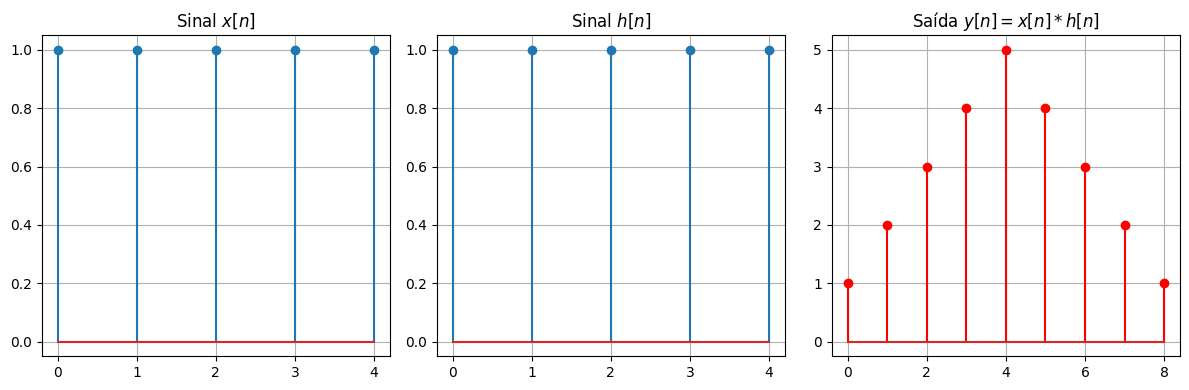

Valores de y[n]: [1. 2. 3. 4. 5. 4. 3. 2. 1.]
Tamanho de y[n]: 9 amostras


In [23]:
import matplotlib.pyplot as plt

#Definindo duas portas
x = np.ones(5)
h = np.ones(5)

#Ajustando o vetor de tempo para os sinais x[n] e h[n]
n_x = list(range(len(x)))
n_h = list(range(len(h)))

#Chamando a função de convolução discreta e o tamanho da saída y
n_y, y = convolucao_discreta(n_x, x, n_h, h)

#Plotando os sinais x[n], h[n] e y[n]
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.stem(n_x, x)
plt.title('Sinal $x[n]$')
plt.grid(True)

plt.subplot(1, 3, 2)
plt.stem(n_h, h)
plt.title('Sinal $h[n]$')
plt.grid(True)

plt.subplot(1, 3, 3)
plt.stem(n_y, y, linefmt='r-', markerfmt='ro')
plt.title('Saída $y[n] = x[n] * h[n]$')
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"Valores de y[n]: {np.array(y)}")
print(f"Tamanho de y[n]: {len(y)} amostras")

### Cálculo Manual da convolução de pulsos retangulares

Seja:
* $x[n] = [1, 1, 1, 1, 1]$ para $n = 0, 1, 2, 3, 4$
* $h[n] = [1, 1, 1, 1, 1]$ para $n = 0, 1, 2, 3, 4$

Lembrando que qualquer valor fora desse intervalo (como $h[-1]$ ou $x[5]$) é igual a zero. O tamanho do sinal de saída $y[n]$ será:

$$N_y = N_x + N_h - 1 = 5 + 5 - 1 = 9 \text{ amostras (índices de } 0 \text{ a } 8)$$

Aplicando a fórmula da convolução discreta (com $k$ indo de $0$ a $4$, intervalo onde $x[k]$ existe):

$$y[n] = \sum_{k=0}^{4} x[k] h[n-k]$$


* **Instante $n = 0$:** (Início da sobreposição)
  $$y[0] = x[0]h[0] = (1 \cdot 1) = 1$$

* **Instante $n = 1$:**
  $$y[1] = x[0]h[1] + x[1]h[0] = 1 + 1 = 2$$

* **Instante $n = 2$:**
  $$y[2] = x[0]h[2] + x[1]h[1] + x[2]h[0] = 1 + 1 + 1 = 3$$

* **Instante $n = 3$:**
  $$y[3] = x[0]h[3] + x[1]h[2] + x[2]h[1] + x[3]h[0] = 1 + 1 + 1 + 1 = 4$$

* **Instante $n = 4$:** (Sobreposição total máxima)
  $$y[4] = x[0]h[4] + x[1]h[3] + x[2]h[2] + x[3]h[1] + x[4]h[0] = 1 + 1 + 1 + 1 + 1 = 5$$

* **Instante $n = 5$:** (O sinal $h[n]$ começa a deslizar para fora de $x[n]$)
  $$y[5] = x[1]h[4] + x[2]h[3] + x[3]h[2] + x[4]h[1] = 1 + 1 + 1 + 1 = 4$$

* **Instante $n = 6$:**
  $$y[6] = x[2]h[4] + x[3]h[3] + x[4]h[2] = 1 + 1 + 1 = 3$$

* **Instante $n = 7$:**
  $$y[7] = x[3]h[4] + x[4]h[3] = 1 + 1 = 2$$

* **Instante $n = 8$:** (Fim da sobreposição)
  $$y[8] = x[4]h[4] = (1 \cdot 1) = 1$$

**Assim:**


$$y[n] = [1, 2, 3, 4, 5, 4, 3, 2, 1]$$

**Portanto o código implementado para convolução "manualmente" está de acordo com a teoria!**

* Usando a bib np.convolve

In [30]:
import numpy as np

x = np.ones(5)
h = np.ones(5)

# Função que realiza a convolução na bib Numpy
y_np = np.convolve(x, h, mode='full')

print(f"Resultado com Numpy: {y_np}")
print(f"Resultado com a função implementada: {np.array(y)}")
print( "Logo, há conformidade entre os dois resultados!!")


Resultado com Numpy: [1. 2. 3. 4. 5. 4. 3. 2. 1.]
Resultado com a função implementada: [1. 2. 3. 4. 5. 4. 3. 2. 1.]
Logo, há conformidade entre os dois resultados!!


## # 3

Análise da complexidade computacional da função de convolução implementada e testes de aceleração de códigos com Numba e Cupy

**Análise da complexidade da função que implementei:**

* Ao analisar a função ("def convolucao_discreta()") que implementei para realizar a operação de convolução discreta observa-se que sua lógica está pautada em dois laços for, onde um está "dentro" do outro. O laço externo percorre cada amostra do sinal de saída, que possui um tamanho total de $N_y = N_x + N_h - 1$. Dentro dele, o laço interno itera sobre as amostras do sinal de entrada, executando a soma acumulada das multiplicações $N_x$ vezes. Devido a essa arquitetura, a complexidade computacional do algoritmo no domínio do tempo é definida como $O(N_x \times N_h)$. Se assumirmos que ambos os sinais possuem um tamanho aproximado $N$, a complexidade se torna $O(N^2)$, indicando um crescimento quadrático. Na prática, isso significa que um aumento no tamanho do sinal exige muito mais do processador, o que se torna um grande gargalo na linguagem Python padrão por ser interpretada e checar variáveis dinamicamente a cada iteração.

**Oque é o Numba?**

* O Numba é um compilador Just-In-Time (JIT) de código aberto, desenvolvido especificamente para otimizar o desempenho numérico da linguagem Python. Sua finalidade principal é acelerar a execução de algoritmos matemáticos e laços de repetição densos que, nativamente, sofreriam com a lentidão do interpretador padrão. Utilizando a infraestrutura de compilação LLVM, o Numba traduz blocos de código Python e operações da biblioteca NumPy diretamente para código de máquina otimizado em tempo de execução. Com isso, ele permite que aplicações científicas e de processamento de sinais alcancem velocidades de cálculo comparáveis às de linguagens compiladas de baixo nível, como C ou C++, mantendo intacta a sintaxe e a facilidade de desenvolvimento originais.

* Ao introduzirmos o Numba, é fundamental compreender que ele não altera a complexidade matemática do algoritmo, que inevitavelmente continua sendo $O(N_x \times N_h)$. O real impacto da ferramenta está na redução drástica do custo de cada operação individual. O decorador @jit (Just-In-Time) intercepta a sua função e a compila inteiramente para código de máquina nativo no exato momento da execução. Essa conversão elimina toda a "burocracia" e o atraso do interpretador Python de dentro dos laços de repetição

In [45]:
import time
import numpy as np
from numba import jit

#Aplica o decorador Just-In-Time (JIT) na função que implementamos
convolucao_numba = jit(nopython=True)(convolucao_discreta)

tamanho = np.arange(0, 2000)
x = porta_discreta(tamanho, tamanho=1500, deslocamento=1000)
h = exponencial_discreta(tamanho, b=0.99, deslocamento=0)

#Função sem a otimização do Numba
print("Rodando sem otimização...")
inicio = time.time()
_, y_manual = convolucao_discreta(tamanho, x, tamanho, h)
print(f"Tempo sem Numba: {time.time() - inicio:.4f} segundos\n")

#Função com a otimização do Numba
print("Rodando com o Numba...")
_ = convolucao_numba(tamanho[:10], x[:10], tamanho[:10], h[:10])

inicio = time.time()
_, y_numba = convolucao_numba(tamanho, x, tamanho, h)
print(f"Tempo com Numba:   {time.time() - inicio:.4f} segundos")

Rodando sem otimização...
Tempo sem Numba: 2.8172 segundos

Rodando com o Numba...
Tempo com Numba:   0.0081 segundos


**O que é e como funciona a biblioteca Cupy?**

* O CuPy é uma biblioteca de código aberto projetada especificamente para a aceleração de cálculos matriciais e de arranjos multidimensionais utilizando Unidades de Processamento Gráfico (GPUs). Sua arquitetura foi desenvolvida para espelhar quase perfeitamente a interface e a sintaxe da biblioteca NumPy, permitindo a transição de códigos baseados em CPU para GPU com modificações mínimas.

* Em sua essência, o CuPy atua como uma interface de alto nível para a arquitetura CUDA (Compute Unified Device Architecture), que é uma plataforma de computação paralela criada pela NVIDIA. A diferença fundamental reside na arquitetura de hardware: enquanto as CPUs são compostas por poucos núcleos complexos (otimizados para processamento sequencial rápido), as GPUs possuem milhares de núcleos mais simples, projetados para processar fluxos massivos de dados em paralelo.

* No contexto de algoritmos como a convolução discreta, o CuPy divide as operações independentes de multiplicação e soma entre esses milhares de núcleos, executando-as simultaneamente. Isso reduz exponencialmente o tempo de processamento quando comparado às iterações sequenciais de um processador convencional.

* Como essa abordagem impõem uma limitação física, ou seja, precisa necessariamente de uma placa da marca Nvidia, vamos usar computação em nuvem através do google collab.

In [46]:
import time
import numpy as np
import cupy as cp
from cupyx.scipy.signal import convolve as convolve_gpu


n_vetor = np.arange(0, 2000)
x_cpu = porta_discreta(n_vetor, tamanho=1500, deslocamento=1000)
h_cpu = exponencial_discreta(n_vetor, b=0.99, deslocamento=0)

#Transferindo dados da CPU para a GPU (VRAM)
x_gpu = cp.asarray(x_cpu)
h_gpu = cp.asarray(h_cpu)


print("Rodando a convolução na GPU (CuPy)...")
cp.cuda.Stream.null.synchronize() #Esse método sincroniza a GPU para garantir a precisão na medição do tempo
inicio = time.time()

#Execução da convolução otima em Hardware em paralelo
y_gpu = convolve_gpu(x_gpu, h_gpu, mode='full')

cp.cuda.Stream.null.synchronize()
fim = time.time()

tempo_cupy = fim - inicio
print(f"Tempo com CuPy (GPU): {tempo_cupy:.4f} segundos")

#Retornando o resultado para Cpu
y_final = cp.asnumpy(y_gpu)

Rodando a convolução na GPU (CuPy)...
Tempo com CuPy (GPU): 0.0021 segundos


* Por fim, a título de comparação vamos fazer a convolução dos mesmos sinais com a np.convolve:

In [48]:
import numpy as np
import time

tamanho = np.arange(0, 2000)
x = porta_discreta(tamanho, tamanho=1500, deslocamento=1000)
h = exponencial_discreta(tamanho, b=0.99, deslocamento=0)

#Marca o inicio da operação
inicio = time.time()
y_numpy = np.convolve(x, h, mode='full')
fim = time.time() #fim

#Ajuste do eico temporal
n_inicial = tamanho[0] + tamanho[0]
n_final = tamanho[-1] + tamanho[-1]
n_y = np.arange(n_inicial, n_final + 1)


print(f"Tempo da convolução com NumPy: {fim - inicio:.4f} segundos")



Tempo da convolução com NumPy: 0.0015 segundos


* Com isso, a implementação inicial sem otimização apresentou o pior desempenho devido às limitações do interpretador Python em lidar com laços aninhados. Ferramentas como o Numba e o CuPy reduziram o tempo de execução de forma drástica (na escala de milissegundos) através da compilação dinâmica e do paralelismo de hardware, respectivamente. Entretanto, a função nativa do NumPy provou ser a mais rápida específicamente por conta do tamanho dos sinais testados, mostrando que a depender da situação, as bibliotecas consolidadas oferecem uma performance boa sem exigir custo adicional de processamento extra.